# Combining the probes

Runs every way of combining the Hindi and Marathi probes for each Marathi budget
in `config.yaml` (25 to 800 labelled sentences), with five seeds, at the main
setting (layer 7, first-piece). It follows the protocol in the readme. All the
analysis is on Marathi dev. The final sections score the same probes once on the
Marathi test split and break the errors down by kind of noun.

In [ ]:
import copy
import json
from collections import defaultdict
from pathlib import Path

import conllu
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from matplotlib.colors import to_rgb
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupKFold

ROOT = Path.cwd()
CONFIG = yaml.safe_load((ROOT / "config.yaml").read_text())
CACHE = ROOT / "data" / "cache"
samples = json.loads((CACHE / "samples.json").read_text())
LAYER, POOLING = CONFIG["main_setting"]["layer"], CONFIG["main_setting"]["pooling"]


class Split:
    """One split's cached features at the main setting, its labels (True = Nom) and its nouns by sentence."""

    def __init__(self, language: str, split: str):
        nouns = json.loads((CACHE / f"{language}_{split}_nouns.json").read_text())
        self.x = np.asarray(np.load(CACHE / f"{language}_{split}_{POOLING}.npy", mmap_mode="r")[LAYER])
        self.y = np.array([noun["label"] == "Nom" for noun in nouns])
        self.sentence = np.array([noun["sentence"] for noun in nouns])
        self.form = np.array([noun["form"] for noun in nouns])
        self.by_sentence = defaultdict(list)
        for k, noun in enumerate(nouns):
            self.by_sentence[noun["sentence"]].append(k)

    def rows(self, sentences) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        """Features, labels and sentence ids of the nouns in these sentences; a sentence listed twice is used twice."""
        keep = [k for s in sentences for k in self.by_sentence[s]]
        return self.x[keep], self.y[keep], self.sentence[keep]

    def replaced(self, x: np.ndarray | None = None, y: np.ndarray | None = None) -> "Split":
        """A copy with different features or labels, used by the controls."""
        out = copy.copy(self)
        out.x = self.x if x is None else x
        out.y = self.y if y is None else y
        return out


hindi, marathi, dev, test = Split("hi", "train"), Split("mr", "train"), Split("mr", "dev"), Split("mr", "test")
majority = max(dev.y.mean(), 1 - dev.y.mean())
print(f"layer {LAYER}, {POOLING}-piece; Marathi dev: {len(dev.y)} nouns, majority {majority:.3f}")

layer 7, first-piece; Marathi dev: 3308 nouns, majority 0.516


## Methods

With a budget of n labelled Marathi sentences:

Every probe chooses its regularisation strength (C) by 5-fold cross-validation
over its own training sentences, so no probe is held back by a setting that
suits a different amount of data.

- **Hindi probe:** trained on the seed's 800 Hindi sentences only.
- **Marathi probe:** trained on 80% of the n sentences, and again on all n.
- **Pooled:** one probe trained on the Hindi sentences plus all n Marathi sentences.
- **Weight blend:** the Hindi and Marathi (80%) probes, each scaled to length 1,
  mixed in one fixed proportion for every noun. The proportion and a shared
  scale and bias are learned on the other 20%.
- **Router:** the same, but the proportion depends on the noun through a gate
  learned on the 20%. How strongly the gate is held back (its penalty) is chosen
  by cross-validation over the 20%'s sentences; "no gate" is one of the choices,
  so the router can fall back to the weight blend.
- **Marathi + Marathi control:** the blend and the router again, with the Hindi
  probe swapped for a second Marathi probe trained on a resample of the same 80%.
  It uses no extra data, so it shows what combining two probes gives on its own.
- **Router, gate also on Hindi:** the Hindi + Marathi router again, but its gate
  (and the shared scale and bias) learns from the 20% plus 200 Hindi sentences
  that the Hindi probe never saw. Hindi data costs nothing in the target
  language, so this gives the gate more to learn from when Marathi is scarce.

The weight blend is exactly the router with a gate that ignores the noun, so any
difference between them comes from choosing per noun.

In [2]:
PENALTIES = [None, 1e4, 1e3, 1e2, 1e1, 1.0, 0.1, 0.01]
CS = [0.001, 0.01, 0.1, 1.0, 10.0]
SHARES = np.round(np.linspace(0, 1, 11), 1)


def probe(x: np.ndarray, y: np.ndarray, groups: np.ndarray) -> LogisticRegressionCV:
    """Train a probe, choosing C by 5-fold cross-validation that keeps each sentence's nouns together."""
    folds = list(GroupKFold(n_splits=5).split(x, y, groups))
    return LogisticRegressionCV(Cs=CS, cv=folds, scoring="neg_log_loss", max_iter=5000).fit(x, y)


def unit(model: LogisticRegression) -> np.ndarray:
    w = model.coef_[0]
    return w / np.linalg.norm(w)


def cosine(u: np.ndarray, w: np.ndarray) -> float:
    return float(u @ w / (np.linalg.norm(u) * np.linalg.norm(w)))


def gate(mix, x) -> np.ndarray:
    """The share g = sigmoid(v·h + c) that the mix gives probe a on each noun."""
    c, _, _, v = mix
    return 1 / (1 + np.exp(-(x @ v + c)))


def logits(mix, x, s_a, s_b) -> np.ndarray:
    """a·(g·s_a + (1 − g)·s_b) + b."""
    _, a, b, _ = mix
    g = gate(mix, x)
    return a * (g * s_a + (1 - g) * s_b) + b


def fit_mix(x, s_a, s_b, y, penalty=None, start=(0.0, 1.0, 0.0)):
    """Learn (c, a, b, v) of `logits` from two probes' scores s_a and s_b.

    With penalty None, v stays 0 and every noun gets the same mix (the weight
    blend); otherwise v is learned with an L2 penalty of that strength (the
    router). Like scikit-learn's C=1, the loss is the summed log loss plus a²/2.
    """
    x, s_a, s_b, y = (torch.as_tensor(t, dtype=torch.float64) for t in (x, s_a, s_b, y))
    c, a, b = (torch.tensor(float(t), dtype=torch.float64, requires_grad=True) for t in start)
    v = torch.zeros(x.shape[1], dtype=torch.float64, requires_grad=penalty is not None)
    optimiser = torch.optim.LBFGS([c, a, b] + ([v] if penalty is not None else []),
                                  max_iter=500, line_search_fn="strong_wolfe")

    def closure():
        optimiser.zero_grad()
        g = torch.sigmoid(x @ v + c)
        out = a * (g * s_a + (1 - g) * s_b) + b
        loss = torch.nn.functional.binary_cross_entropy_with_logits(out, y, reduction="sum") + a * a / 2
        if penalty is not None:
            loss = loss + penalty * (v @ v) / 2
        loss.backward()
        return loss

    optimiser.step(closure)
    return c.item(), a.item(), b.item(), v.detach().numpy()


def combine(w_a: np.ndarray, w_b: np.ndarray, x: np.ndarray, y: np.ndarray, groups: np.ndarray):
    """Fit the weight blend and the router of two length-1 probes on these nouns (groups = their sentences)."""
    order = {group: i for i, group in enumerate(dict.fromkeys(groups))}
    k = min(5, len(order))
    fold = np.array([order[group] % k for group in groups])
    s_a, s_b = x @ w_a, x @ w_b
    blend = fit_mix(x, s_a, s_b, y)

    def held_out_loss(penalty):
        loss = 0.0
        for f in range(k):
            train, test = fold != f, fold == f
            mix = fit_mix(x[train], s_a[train], s_b[train], y[train], penalty, blend[:3])
            z = logits(mix, x[test], s_a[test], s_b[test])
            loss += np.logaddexp(0, -np.where(y[test], z, -z)).sum()
        return loss

    penalty = min(PENALTIES, key=held_out_loss)
    router = blend if penalty is None else fit_mix(x, s_a, s_b, y, penalty, blend[:3])
    return blend, router, penalty


def fixed_mixes(w_a: np.ndarray, w_b: np.ndarray, x: np.ndarray, y: np.ndarray) -> list:
    """For each share λ in SHARES, the probe λ·w_a + (1 − λ)·w_b with only its scale and bias refit on these nouns."""
    out = []
    for share in SHARES:
        w = share * w_a + (1 - share) * w_b
        out.append((w, LogisticRegression().fit((x @ w)[:, None], y)))
    return out

## Sweep

For each seed, the Marathi budget is the first n sentences of the seed's
Marathi order, so smaller budgets sit inside larger ones. The first 80% of the
budget trains the Marathi probes; the last 20% is held out for the blend and
the router. Takes under an hour.

In [3]:
def sweep(hindi: Split, marathi: Split, dev: Split, sizes: list[int], test: Split | None = None,
          extras: bool = True):
    """Run every method for each seed and Marathi budget.

    Returns {"dev": (runs, correct, gates)}, where correct[seed, n][method] says
    which nouns the method got right and gates[seed, n][router] is the Hindi share
    the router gives each noun. With a test split, also {"test": ...}, scored with
    the same probes. The extras (the router whose gate also learns from Hindi,
    the fixed mixes and the cosines) are skipped by the controls.
    """
    share = CONFIG["router_share"]
    splits = {"dev": dev} | ({"test": test} if test is not None else {})
    out = {name: ([], {}, {}) for name in splits}
    for seed in map(str, CONFIG["seeds"]):
        rng = np.random.default_rng(int(seed))
        hindi_x, hindi_y, hindi_g = hindi.rows(samples["hi"][seed])
        hindi_probe = probe(hindi_x, hindi_y, hindi_g)
        if extras:
            # A separate generator, so the main methods draw the same numbers as without the extras.
            extra_rng = np.random.default_rng([int(seed), 1])
            half = len(samples["hi"][seed]) // 2
            hindi_halves = [probe(*hindi.rows(samples["hi"][seed][:half])),
                            probe(*hindi.rows(samples["hi"][seed][half:]))]
            shuffled_hindi = probe(hindi_x, extra_rng.permutation(hindi_y), hindi_g)
            unseen = sorted(set(hindi.by_sentence) - set(samples["hi"][seed]))
            gate_x, gate_y, gate_g = hindi.rows(extra_rng.choice(unseen, CONFIG["router_hindi_sentences"],
                                                                 replace=False))
        for n in sizes:
            budget = samples["mr"][seed][:n]
            cut = round(n * (1 - share))
            probe_part, router_part = budget[:cut], budget[cut:]
            marathi_probe = probe(*marathi.rows(probe_part))
            resampled_probe = probe(*marathi.rows(rng.choice(probe_part, len(probe_part))))
            marathi_x, marathi_y, marathi_g = marathi.rows(budget)
            # Hindi sentence ids are made negative so they never share a fold with Marathi ones.
            probes = {
                "hindi": hindi_probe,
                "marathi_80": marathi_probe,
                "marathi_100": probe(marathi_x, marathi_y, marathi_g),
                "pooled": probe(np.vstack([hindi_x, marathi_x]), np.concatenate([hindi_y, marathi_y]),
                                np.concatenate([-1 - hindi_g, marathi_g])),
            }
            info = {"seed": int(seed), "n": n} | {f"C_{name}": float(model.C_[0]) for name, model in probes.items()}
            router_x, router_y, router_g = marathi.rows(router_part)
            mixes = {}
            for name, other in [("hm", hindi_probe), ("mm", resampled_probe)]:
                w_a, w_b = unit(other), unit(marathi_probe)
                blend, router, penalty = combine(w_a, w_b, router_x, router_y, router_g)
                mixes[name] = w_a, w_b, blend, router
                info[f"other_share_{name}"] = 1 / (1 + np.exp(-blend[0]))
                info[f"penalty_{name}"] = penalty
            fixed = {}
            if extras:
                w_h, w_m = unit(hindi_probe), unit(marathi_probe)
                # The gate's Hindi sentences get negative ids too, so no fold splits a sentence.
                _, router, penalty = combine(w_h, w_m, np.vstack([router_x, gate_x]),
                                             np.concatenate([router_y, gate_y]),
                                             np.concatenate([router_g, -1 - gate_g]))
                mixes["mixed"] = w_h, w_m, None, router
                info["penalty_mixed"] = penalty
                for name, other in [("hm", hindi_probe), ("shuffled", shuffled_hindi), ("mm", resampled_probe)]:
                    fixed[name] = fixed_mixes(unit(other), w_m, router_x, router_y)
                g = info["other_share_hm"]
                w_blend = g * w_h + (1 - g) * w_m
                info |= {
                    "cos_hindi_marathi": cosine(w_h, w_m),
                    "cos_blend_hindi": cosine(w_blend, w_h),
                    "cos_blend_marathi": cosine(w_blend, w_m),
                    "cos_pooled_hindi": cosine(unit(probes["pooled"]), w_h),
                    "cos_pooled_marathi": cosine(unit(probes["pooled"]), unit(probes["marathi_100"])),
                    "cos_marathi_resample": cosine(unit(resampled_probe), w_m),
                    "cos_hindi_halves": cosine(*map(unit, hindi_halves)),
                }
            for split_name, split in splits.items():
                right = {name: model.predict(split.x) == split.y for name, model in probes.items()}
                gates = {}
                for name, (w_a, w_b, blend, router) in mixes.items():
                    s_a, s_b = split.x @ w_a, split.x @ w_b
                    if blend is not None:
                        right[f"blend_{name}"] = (logits(blend, split.x, s_a, s_b) > 0) == split.y
                    right[f"router_{name}"] = (logits(router, split.x, s_a, s_b) > 0) == split.y
                    if name != "mm":
                        gates[f"router_{name}"] = gate(router, split.x)
                # Binary labels, so a wrong answer is the other class.
                f1 = {f"f1_{method}": f1_score(split.y, np.where(hits, split.y, ~split.y), average="macro")
                      for method, hits in right.items()}
                lines = {f"fixed_{name}": [float(np.mean(model.predict((split.x @ w)[:, None]) == split.y))
                                           for w, model in mix] for name, mix in fixed.items()}
                runs, correct, gates_by_run = out[split_name]
                runs.append(info | {method: hits.mean() for method, hits in right.items()} | f1 | lines)
                correct[int(seed), n] = right
                gates_by_run[int(seed), n] = gates
            run = out["dev"][0][-1]
            print(f"seed {seed}, n {n:3d}: " + ", ".join(
                f"{key} {run[key]:.3f}" for key in ["marathi_100", "pooled", "blend_hm", "router_hm", "router_mixed"]
                if key in run), flush=True)
    return out


by_split = sweep(hindi, marathi, dev, CONFIG["marathi_train_sentences"], test)
runs, correct, gates = by_split["dev"]

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

... (146 outputs left out)

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

seed 89, n 800: marathi_100 0.913, pooled 0.907, blend_hm 0.910, router_hm 0.912, router_mixed 0.903


## Results

Mean ± standard deviation over the five seeds. `other share` is the part of the
blend given to the Hindi probe (or to the second Marathi probe in the control).
Macro-F1 is the average of the F1 scores for Nom and for Acc, so it counts
mistakes on both cases equally even though Nom is a little more common.

Accuracy
n                                        25             50            100            200            400            800
Hindi probe                     0.856 ±0.004    0.856 ±0.004    0.856 ±0.004    0.856 ±0.004    0.856 ±0.004    0.856 ±0.004
Marathi probe, 80%              0.728 ±0.007    0.804 ±0.013    0.846 ±0.004    0.868 ±0.011    0.888 ±0.004    0.908 ±0.003
Marathi probe, all n            0.753 ±0.027    0.818 ±0.012    0.856 ±0.004    0.876 ±0.005    0.896 ±0.004    0.912 ±0.003
Pooled data                     0.859 ±0.006    0.860 ±0.007    0.868 ±0.006    0.876 ±0.005    0.890 ±0.004    0.902 ±0.006
Blend, Hindi + Marathi          0.831 ±0.038    0.844 ±0.007    0.872 ±0.004    0.883 ±0.010    0.898 ±0.003    0.909 ±0.003
Router, Hindi + Marathi         0.823 ±0.051    0.834 ±0.007    0.874 ±0.006    0.883 ±0.010    0.896 ±0.005    0.910 ±0.003
Router, gate also on Hindi      0.856 ±0.004    0.859 ±0.004    0.862 ±0.004    0.873 ±0.007    0.886 ±0.004    0.899 ±0.0

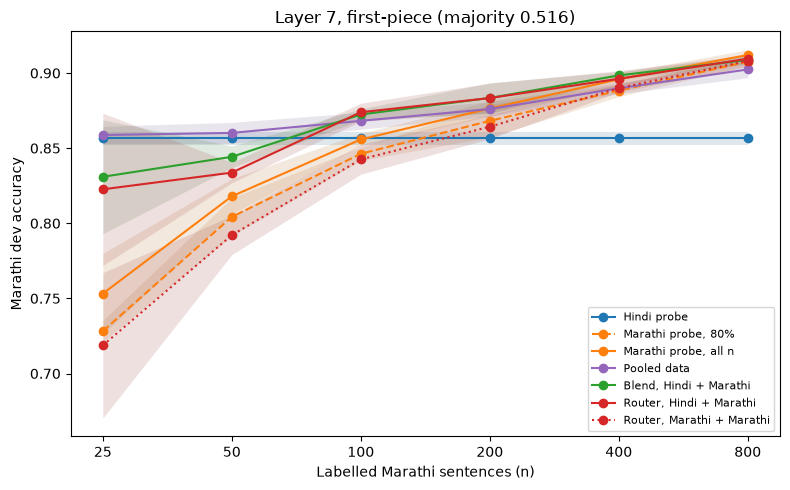

In [4]:
methods = {
    "hindi": "Hindi probe",
    "marathi_80": "Marathi probe, 80%",
    "marathi_100": "Marathi probe, all n",
    "pooled": "Pooled data",
    "blend_hm": "Blend, Hindi + Marathi",
    "router_hm": "Router, Hindi + Marathi",
    "router_mixed": "Router, gate also on Hindi",
    "blend_mm": "Blend, Marathi + Marathi",
    "router_mm": "Router, Marathi + Marathi",
    "other_share_hm": "Hindi share of blend",
    "other_share_mm": "2nd Marathi share of blend",
}
scored = [key for key in methods if not key.startswith("other_share")]
sizes = CONFIG["marathi_train_sentences"]


def summarise(runs: list[dict], keys: list[str]) -> dict:
    return {key: {n: {"mean": np.mean([r[key] for r in runs if r["n"] == n]),
                      "std": np.std([r[key] for r in runs if r["n"] == n])} for n in sizes} for key in keys}


def show(summary: dict, labels: dict) -> None:
    print(f"{'n':28s}" + "".join(f"{n:>15d}" for n in sizes))
    for key, label in labels.items():
        print(f"{label:28s}" + "".join(f"{summary[key][n]['mean']:9.3f} ±{summary[key][n]['std']:.3f}" for n in sizes))


summary = summarise(runs, list(methods))
f1_summary = summarise(runs, [f"f1_{key}" for key in scored])
result = {"layer": LAYER, "pooling": POOLING, "split": "mr dev", "majority": majority,
          "summary": summary, "macro_f1": f1_summary, "runs": runs}
(ROOT / "results" / "combination.json").write_text(json.dumps(result, indent=2) + "\n")

print("Accuracy")
show(summary, methods)
print("\nMacro-F1")
show(f1_summary, {f"f1_{key}": methods[key] for key in scored})
print("\nC chosen by each probe, per seed:")
for name in ["hindi", "marathi_80", "marathi_100", "pooled"]:
    print(f"  {name}:", {n: [r[f"C_{name}"] for r in runs if r["n"] == n] for n in sizes})
print("\nRouter penalty chosen (None = fell back to the blend):")
for name in ["hm", "mm", "mixed"]:
    print(f"  {name}:", {n: [r[f"penalty_{name}"] for r in runs if r["n"] == n] for n in sizes})

figure, ax = plt.subplots(figsize=(8, 5))
lines = [("hindi", "C0", "-"), ("marathi_80", "C1", "--"), ("marathi_100", "C1", "-"),
         ("pooled", "C4", "-"), ("blend_hm", "C2", "-"), ("router_hm", "C3", "-"), ("router_mm", "C3", ":")]
for key, color, style in lines:
    mean = np.array([summary[key][n]["mean"] for n in sizes])
    std = np.array([summary[key][n]["std"] for n in sizes])
    # The band is the line's colour mixed half-way with grey.
    band = 0.5 * np.array(to_rgb(color)) + 0.5 * np.array(to_rgb("grey"))
    ax.fill_between(sizes, mean - std, mean + std, color=band, alpha=0.18, linewidth=0)
    ax.plot(sizes, mean, color=color, linestyle=style, marker="o", label=methods[key])
ax.set(xscale="log", xticks=sizes, xticklabels=sizes, xlabel="Labelled Marathi sentences (n)",
       ylabel="Marathi dev accuracy", title=f"Layer {LAYER}, {POOLING}-piece (majority {majority:.3f})")
ax.minorticks_off()
ax.legend(fontsize=8)
figure.tight_layout()
figure.savefig(ROOT / "results" / "combination.png", dpi=150)
plt.show()

## Are the differences real?

Compares pairs of methods on the same Marathi dev nouns. Nouns in one sentence
are not independent, so the sentence is the unit that gets resampled. For each
pair and budget the table shows:

- **difference:** how many points the first method is ahead, averaged over the seeds;
- **95% interval:** from 10,000 bootstrap resamples of the dev sentences;
- **p:** how often randomly swapping the two methods' answers, sentence by sentence,
  gives a difference at least this large;
- **Holm p:** p corrected for running all these comparisons at once;
- **seeds won:** in how many of the five seeds the first method scored higher.

The interval and p only cover which dev sentences we happened to have. How much
the result changes with a different training sample shows in the seeds-won
column and in the ± of the results table.

The router whose gate also learns from Hindi is tested in a second, separate
table, so adding it leaves the corrected p of the main comparisons unchanged.

In [5]:
from statsmodels.stats.multitest import multipletests

comparisons = [
    ("blend_hm", "marathi_100"),   # does the blend beat Marathi alone with the same data?
    ("router_hm", "blend_hm"),     # does choosing per noun add anything?
    ("blend_hm", "pooled"),        # is blending better than pooling the data?
    ("blend_mm", "marathi_100"),   # control: does combining help without Hindi?
]
gate_comparisons = [
    ("router_mixed", "router_hm"),  # does a gate that also learns from Hindi beat the Marathi-only gate?
    ("router_mixed", "blend_hm"),   # does it beat the plain blend?
]
seeds = [int(seed) for seed in CONFIG["seeds"]]


def significance(correct: dict, split: Split, path: Path, comparisons: list[tuple]) -> list[dict]:
    # Paired tests of each comparison at each budget, resampling the split's sentences.
    sentence = np.unique(split.sentence, return_inverse=True)[1]
    nouns_per_sentence = np.bincount(sentence)
    rng = np.random.default_rng(0)
    draws = rng.integers(0, len(nouns_per_sentence), (10_000, len(nouns_per_sentence)))
    flips = rng.choice([-1.0, 1.0], draws.shape)
    rows = []
    for a, b in comparisons:
        for n in sizes:
            # Per sentence: right answers of a minus those of b, averaged over the seeds.
            diff = np.mean([np.bincount(sentence, correct[seed, n][a] * 1.0 - correct[seed, n][b])
                            for seed in seeds], axis=0)
            observed = diff.sum() / len(sentence)
            boot = diff[draws].sum(1) / nouns_per_sentence[draws].sum(1)
            swapped = (flips * diff).sum(1) / len(sentence)
            rows.append({
                "a": a, "b": b, "n": n, "difference": observed,
                "low": np.percentile(boot, 2.5), "high": np.percentile(boot, 97.5),
                "p": (np.sum(np.abs(swapped) >= abs(observed)) + 1) / (len(swapped) + 1),
                "seeds_won": int(sum(correct[seed, n][a].mean() > correct[seed, n][b].mean() for seed in seeds)),
            })
    for row, holm in zip(rows, multipletests([row["p"] for row in rows], method="holm")[1]):
        row["holm_p"] = holm
    path.write_text(json.dumps(rows, indent=2) + "\n")

    print(f"{'comparison':52s}{'n':>5s}{'difference':>12s}{'95% interval':>18s}{'p':>9s}{'Holm p':>9s}{'seeds won':>11s}")
    for t in rows:
        print(f"{methods[t['a']] + ' vs ' + methods[t['b']]:52s}{t['n']:5d}{100 * t['difference']:+11.1f} "
              f"  [{100 * t['low']:+5.1f}, {100 * t['high']:+5.1f}]{t['p']:9.4f}{t['holm_p']:9.4f}{t['seeds_won']:8d}/{len(seeds)}")
    return rows


tests = significance(correct, dev, ROOT / "results" / "significance.json", comparisons)
print()
gate_tests = significance(correct, dev, ROOT / "results" / "significance_gate.json", gate_comparisons)

comparison                                              n  difference      95% interval        p   Holm p  seeds won
Blend, Hindi + Marathi vs Marathi probe, all n         25       +7.8   [ +6.9,  +8.6]   0.0001   0.0024       5/5
Blend, Hindi + Marathi vs Marathi probe, all n         50       +2.6   [ +2.0,  +3.3]   0.0001   0.0024       4/5
Blend, Hindi + Marathi vs Marathi probe, all n        100       +1.7   [ +1.0,  +2.3]   0.0001   0.0024       5/5
Blend, Hindi + Marathi vs Marathi probe, all n        200       +0.7   [ +0.3,  +1.1]   0.0016   0.0144       4/5
Blend, Hindi + Marathi vs Marathi probe, all n        400       +0.3   [ -0.1,  +0.6]   0.1623   0.6491       3/5
Blend, Hindi + Marathi vs Marathi probe, all n        800       -0.3   [ -0.6,  -0.0]   0.0314   0.2198       0/5
Router, Hindi + Marathi vs Blend, Hindi + Marathi      25       -0.8   [ -1.1,  -0.6]   0.0001   0.0024       0/5
Router, Hindi + Marathi vs Blend, Hindi + Marathi      50       -1.1   [ -1.4,  -0.7]

comparison                                              n  difference      95% interval        p   Holm p  seeds won
Router, gate also on Hindi vs Router, Hindi + Marathi   25       +3.3   [ +2.8,  +3.9]   0.0001   0.0012       4/5
Router, gate also on Hindi vs Router, Hindi + Marathi   50       +2.5   [ +1.8,  +3.2]   0.0001   0.0012       5/5
Router, gate also on Hindi vs Router, Hindi + Marathi  100       -1.2   [ -1.8,  -0.6]   0.0001   0.0012       1/5
Router, gate also on Hindi vs Router, Hindi + Marathi  200       -1.1   [ -1.6,  -0.5]   0.0005   0.0012       1/5
Router, gate also on Hindi vs Router, Hindi + Marathi  400       -1.0   [ -1.4,  -0.6]   0.0001   0.0012       1/5
Router, gate also on Hindi vs Router, Hindi + Marathi  800       -1.1   [ -1.5,  -0.7]   0.0001   0.0012       0/5
Router, gate also on Hindi vs Blend, Hindi + Marathi   25       +2.5   [ +2.0,  +3.0]   0.0001   0.0012       4/5
Router, gate also on Hindi vs Blend, Hindi + Marathi   50       +1.4   [ +0.9, 

## Fixed mixes

Each point fixes the Hindi share λ of the blend, from 0 (the Marathi probe on
80%) to 1 (the Hindi probe alone), and refits only the shared scale and bias on
the 20%. The same curve is drawn with a Hindi probe trained on shuffled labels,
and with the second Marathi probe in place of the Hindi one. The dotted lines
are the share the blend actually learned. The best point of a curve is picked by
looking at dev, so the curves are only an illustration: the learned share is the
result.

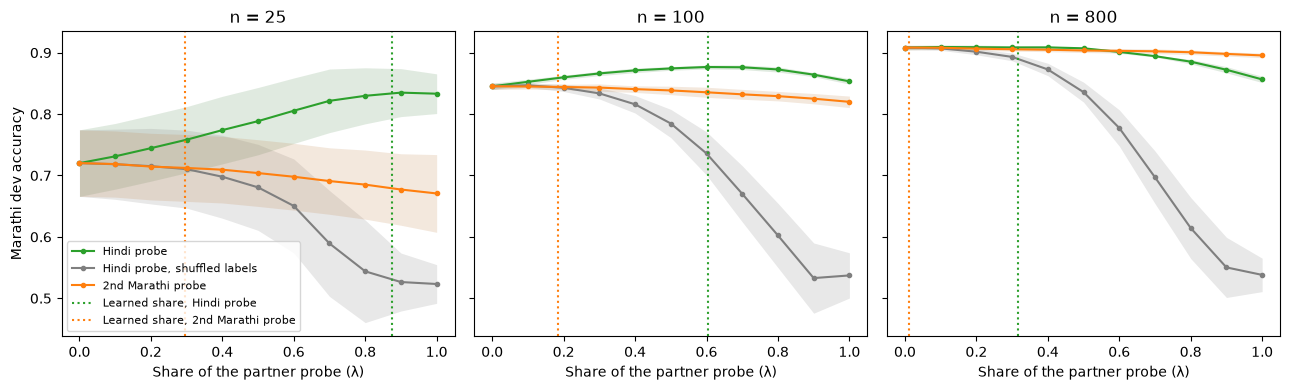

In [6]:
MIX_SIZES = [25, 100, 800]
partners = {"hm": ("Hindi probe", "C2"), "shuffled": ("Hindi probe, shuffled labels", "C7"),
            "mm": ("2nd Marathi probe", "C1")}
mix_summary = {name: {n: {"mean": np.mean([r[f"fixed_{name}"] for r in runs if r["n"] == n], axis=0).tolist(),
                          "std": np.std([r[f"fixed_{name}"] for r in runs if r["n"] == n], axis=0).tolist()}
                      for n in MIX_SIZES} for name in partners}
(ROOT / "results" / "mixes.json").write_text(json.dumps(
    {"shares": SHARES.tolist(), "split": "mr dev", "summary": mix_summary}, indent=2) + "\n")

figure, axes = plt.subplots(1, len(MIX_SIZES), figsize=(13, 4), sharey=True)
for ax, n in zip(axes, MIX_SIZES):
    for name, (label, color) in partners.items():
        mean, std = np.array(mix_summary[name][n]["mean"]), np.array(mix_summary[name][n]["std"])
        band = 0.5 * np.array(to_rgb(color)) + 0.5 * np.array(to_rgb("grey"))
        ax.fill_between(SHARES, mean - std, mean + std, color=band, alpha=0.18, linewidth=0)
        ax.plot(SHARES, mean, color=color, marker="o", markersize=3, label=label)
    for name in ["hm", "mm"]:
        ax.axvline(summary[f"other_share_{name}"][n]["mean"], color=partners[name][1], linestyle=":",
                   label=f"Learned share, {partners[name][0]}")
    ax.set(title=f"n = {n}", xlabel="Share of the partner probe (λ)")
axes[0].set_ylabel("Marathi dev accuracy")
axes[0].legend(fontsize=8)
figure.tight_layout()
figure.savefig(ROOT / "results" / "mixes.png", dpi=150)
plt.show()

## Probe directions

The cosine between two probes' weight vectors: 1 means they point the same way,
0 means unrelated directions. For scale, two Hindi probes trained on the two
halves of the seed's Hindi sentences show how much the direction moves with a
different sample from the same language.

In [7]:
cosines = {
    "cos_hindi_marathi": "Hindi vs Marathi (80%)",
    "cos_blend_hindi": "Blend vs Hindi",
    "cos_blend_marathi": "Blend vs Marathi (80%)",
    "cos_pooled_hindi": "Pooled vs Hindi",
    "cos_pooled_marathi": "Pooled vs Marathi (all n)",
    "cos_marathi_resample": "Marathi vs its resample",
    "cos_hindi_halves": "Hindi halves (for scale)",
}
cosine_summary = summarise(runs, list(cosines))
(ROOT / "results" / "cosines.json").write_text(json.dumps(
    {"layer": LAYER, "pooling": POOLING, "summary": cosine_summary}, indent=2) + "\n")
show(cosine_summary, cosines)

n                                        25             50            100            200            400            800
Hindi vs Marathi (80%)          0.257 ±0.015    0.335 ±0.023    0.379 ±0.021    0.419 ±0.020    0.444 ±0.036    0.509 ±0.012
Blend vs Hindi                  0.984 ±0.022    0.881 ±0.116    0.876 ±0.098    0.758 ±0.171    0.758 ±0.032    0.748 ±0.033
Blend vs Marathi (80%)          0.385 ±0.114    0.675 ±0.167    0.729 ±0.153    0.856 ±0.131    0.918 ±0.030    0.950 ±0.018
Pooled vs Hindi                 0.989 ±0.004    0.978 ±0.004    0.953 ±0.008    0.912 ±0.010    0.872 ±0.004    0.834 ±0.008
Pooled vs Marathi (all n)       0.329 ±0.016    0.418 ±0.016    0.508 ±0.011    0.600 ±0.023    0.704 ±0.064    0.814 ±0.049
Marathi vs its resample         0.794 ±0.058    0.849 ±0.032    0.836 ±0.023    0.853 ±0.028    0.855 ±0.044    0.921 ±0.005
Hindi halves (for scale)        0.598 ±0.026    0.598 ±0.026    0.598 ±0.026    0.598 ±0.026    0.598 ±0.026    0.598 ±0.026


## Controls

Three checks that the results come from what mBERT knows about case, not from
memorising words or from a leak in the setup. Each one reruns the sweep at 25,
100 and 800 Marathi sentences with one thing swapped out:

- **Random word vectors:** every word form gets a fixed random vector in place of
  mBERT's. A probe can then only memorise which forms tend to be Nom or Acc. A
  form spelt the same in Hindi and Marathi gets the same vector.
- **Shuffled labels:** the Hindi and Marathi training labels are shuffled once,
  and every method uses the same shuffled labels; the dev labels stay real.
  Every method should fall to about the majority rate.
- **Control task:** every word form gets a random label, Nom or Acc, in the same
  proportions as the real labels, kept the same wherever the form appears
  (train and dev). It shows how well a probe does by memorising forms alone. The
  gap between the real task and this one (selectivity) is the part that needs
  mBERT's knowledge of case.

In [8]:
CONTROL_SIZES = [25, 100, 800]
rng = np.random.default_rng(0)
forms = sorted(set(hindi.form) | set(marathi.form) | set(dev.form))

vector = dict(zip(forms, rng.normal(size=(len(forms), hindi.x.shape[1])).astype(np.float32)))
control_label = dict(zip(forms, rng.random(len(forms)) < np.concatenate([hindi.y, marathi.y]).mean()))
controls = {
    "random_vectors": [split.replaced(x=np.stack([vector[f] for f in split.form])) for split in (hindi, marathi, dev)],
    "shuffled_labels": [hindi.replaced(y=rng.permutation(hindi.y)), marathi.replaced(y=rng.permutation(marathi.y)), dev],
    "control_task": [split.replaced(y=np.array([control_label[f] for f in split.form])) for split in (hindi, marathi, dev)],
}

control_runs = {"real": [run for run in runs if run["n"] in CONTROL_SIZES]}
control_majority = {"real": majority}
for name, splits in controls.items():
    print(f"--- {name}")
    control_runs[name] = sweep(*splits, CONTROL_SIZES, extras=False)["dev"][0]
    control_majority[name] = max(splits[2].y.mean(), 1 - splits[2].y.mean())

shown = ["hindi", "marathi_100", "pooled", "blend_hm", "router_hm"]
control_summary = {
    name: {key: {n: np.mean([r[key] for r in group if r["n"] == n]) for n in CONTROL_SIZES} for key in shown}
    for name, group in control_runs.items()
}
(ROOT / "results" / "controls.json").write_text(json.dumps(
    {"sizes": CONTROL_SIZES, "majority": control_majority, "summary": control_summary, "runs": control_runs},
    indent=2) + "\n")

print(f"\nMean Marathi dev accuracy over the seeds, for n = {CONTROL_SIZES}")
for name, summary_ in control_summary.items():
    print(f"\n{name} (majority {control_majority[name]:.3f})")
    for key in shown:
        print(f"  {methods[key]:28s}" + "".join(f"{summary_[key][n]:8.3f}" for n in CONTROL_SIZES))
print("\nSelectivity (real task minus control task), in points")
for key in shown:
    print(f"  {methods[key]:28s}" + "".join(
        f"{100 * (control_summary['real'][key][n] - control_summary['control_task'][key][n]):+8.1f}"
        for n in CONTROL_SIZES))

--- random_vectors


/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

seed 13, n  25: marathi_100 0.521, pooled 0.528, blend_hm 0.498, router_hm 0.498


/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

... (205 outputs left out)

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

seed 89, n 800: marathi_100 0.563, pooled 0.574, blend_hm 0.535, router_hm 0.535



Mean Marathi dev accuracy over the seeds, for n = [25, 100, 800]

real (majority 0.516)
  Hindi probe                    0.856   0.856   0.856
  Marathi probe, all n           0.753   0.856   0.912
  Pooled data                    0.859   0.868   0.902
  Blend, Hindi + Marathi         0.831   0.872   0.909
  Router, Hindi + Marathi        0.823   0.874   0.910

random_vectors (majority 0.516)
  Hindi probe                    0.522   0.522   0.522
  Marathi probe, all n           0.505   0.555   0.618
  Pooled data                    0.522   0.538   0.604
  Blend, Hindi + Marathi         0.494   0.536   0.618
  Router, Hindi + Marathi        0.493   0.537   0.618

shuffled_labels (majority 0.516)
  Hindi probe                    0.479   0.479   0.479
  Marathi probe, all n           0.498   0.499   0.493
  Pooled data                    0.484   0.486   0.481
  Blend, Hindi + Marathi         0.499   0.529   0.517
  Router, Hindi + Marathi        0.500   0.529   0.517

control_task (majo

## Final test

The same probes, scored once on the Marathi test split. Every setting was fixed
beforehand: layer 7 and first-piece pooling were chosen on dev, and C, the
blend, and the router's penalty are all learned from the training budget, so
nothing here was tuned on test.

Macro-F1, the router whose gate also learns from Hindi, and the noun breakdown
below were added after the first test run. They change no setting of the
methods scored then, and the new router's settings were fixed without looking
at test.

In [9]:
test_runs, test_correct, test_gates = by_split["test"]
test_majority = max(test.y.mean(), 1 - test.y.mean())
test_summary = summarise(test_runs, scored)
test_f1 = summarise(test_runs, [f"f1_{key}" for key in scored])
(ROOT / "results" / "test.json").write_text(json.dumps(
    {"layer": LAYER, "pooling": POOLING, "split": "mr test", "majority": test_majority,
     "summary": test_summary, "macro_f1": test_f1, "runs": test_runs}, indent=2) + "\n")

print(f"Marathi test: {len(test.y)} nouns, majority {test_majority:.3f}\n")
print("Accuracy")
show(test_summary, {key: methods[key] for key in scored})
print("\nMacro-F1")
show(test_f1, {f"f1_{key}": methods[key] for key in scored})
print()
test_tests = significance(test_correct, test, ROOT / "results" / "test_significance.json", comparisons)
print()
test_gate_tests = significance(test_correct, test, ROOT / "results" / "test_significance_gate.json",
                               gate_comparisons)

Marathi test: 3391 nouns, majority 0.536

Accuracy
n                                        25             50            100            200            400            800
Hindi probe                     0.840 ±0.004    0.840 ±0.004    0.840 ±0.004    0.840 ±0.004    0.840 ±0.004    0.840 ±0.004
Marathi probe, 80%              0.717 ±0.012    0.794 ±0.021    0.840 ±0.010    0.868 ±0.012    0.886 ±0.006    0.902 ±0.004
Marathi probe, all n            0.738 ±0.026    0.814 ±0.017    0.849 ±0.011    0.876 ±0.008    0.888 ±0.004    0.906 ±0.005
Pooled data                     0.842 ±0.005    0.847 ±0.006    0.855 ±0.007    0.869 ±0.004    0.879 ±0.003    0.894 ±0.003
Blend, Hindi + Marathi          0.815 ±0.042    0.833 ±0.017    0.863 ±0.011    0.875 ±0.014    0.894 ±0.003    0.903 ±0.002
Router, Hindi + Marathi         0.806 ±0.057    0.825 ±0.014    0.864 ±0.012    0.876 ±0.015    0.893 ±0.006    0.902 ±0.002
Router, gate also on Hindi      0.841 ±0.004    0.843 ±0.002    0.848 ±0.004    

comparison                                              n  difference      95% interval        p   Holm p  seeds won
Blend, Hindi + Marathi vs Marathi probe, all n         25       +7.6   [ +6.8,  +8.5]   0.0001   0.0024       5/5
Blend, Hindi + Marathi vs Marathi probe, all n         50       +1.9   [ +1.2,  +2.6]   0.0001   0.0024       4/5
Blend, Hindi + Marathi vs Marathi probe, all n        100       +1.3   [ +0.7,  +2.0]   0.0003   0.0033       5/5
Blend, Hindi + Marathi vs Marathi probe, all n        200       -0.1   [ -0.6,  +0.4]   0.7782   1.0000       2/5
Blend, Hindi + Marathi vs Marathi probe, all n        400       +0.5   [ +0.1,  +1.0]   0.0105   0.0945       4/5
Blend, Hindi + Marathi vs Marathi probe, all n        800       -0.3   [ -0.6,  -0.1]   0.0171   0.1368       2/5
Router, Hindi + Marathi vs Blend, Hindi + Marathi      25       -0.9   [ -1.2,  -0.6]   0.0001   0.0024       0/5
Router, Hindi + Marathi vs Blend, Hindi + Marathi      50       -0.8   [ -1.1,  -0.4]

comparison                                              n  difference      95% interval        p   Holm p  seeds won
Router, gate also on Hindi vs Router, Hindi + Marathi   25       +3.5   [ +3.0,  +4.0]   0.0001   0.0012       4/5
Router, gate also on Hindi vs Router, Hindi + Marathi   50       +1.8   [ +1.1,  +2.4]   0.0001   0.0012       5/5
Router, gate also on Hindi vs Router, Hindi + Marathi  100       -1.6   [ -2.3,  -1.1]   0.0001   0.0012       1/5
Router, gate also on Hindi vs Router, Hindi + Marathi  200       -1.5   [ -2.2,  -0.9]   0.0001   0.0012       1/5
Router, gate also on Hindi vs Router, Hindi + Marathi  400       -1.7   [ -2.2,  -1.2]   0.0001   0.0012       1/5
Router, gate also on Hindi vs Router, Hindi + Marathi  800       -1.3   [ -1.7,  -0.9]   0.0001   0.0012       0/5
Router, gate also on Hindi vs Blend, Hindi + Marathi   25       +2.6   [ +2.2,  +3.1]   0.0001   0.0012       4/5
Router, gate also on Hindi vs Blend, Hindi + Marathi   50       +1.0   [ +0.4, 

## Which nouns does Hindi help on?

Splits the nouns by four properties and shows each method's accuracy on each
group, averaged over the seeds:

- **Case:** Nom or Acc.
- **Seen in the Marathi budget:** whether the noun's exact form occurs among the
  n labelled Marathi sentences, and with one case or both. A probe can only have
  memorised forms it has seen.
- **Also a Hindi noun:** whether the same spelling occurs as a noun in the Hindi
  training treebank.
- **Postposition next:** whether the next word is a separate postposition, the
  way Hindi writes its case markers. Marathi almost always attaches the marker to
  the noun instead, so this group is tiny.

`gain` is the blend minus the Marathi probe trained on all n, in points.
`gate` is the average share the router gives the Hindi probe on that group.

The second table asks what the router routes on: it splits the nouns by which of
its two probes (Hindi, and Marathi on 80%) gets them right, and shows the
average Hindi share each router gives.

In [10]:
ANALYSIS_SIZES = [25, 100, 800]


def read_words(language: str, split: str) -> list[list]:
    prefix = CONFIG["treebanks"][language]["prefix"]
    with (ROOT / "data" / "raw" / language / f"{prefix}-ud-{split}.conllu").open(encoding="utf-8") as stream:
        return [[token for token in sentence if isinstance(token["id"], int)] for sentence in conllu.parse_incr(stream)]


hindi_nouns = {token["form"] for sentence in read_words("hi", "train") for token in sentence if token["upos"] == "NOUN"}


def next_is_postposition(split_name: str) -> np.ndarray:
    words = read_words("mr", split_name)
    nouns = json.loads((CACHE / f"mr_{split_name}_nouns.json").read_text())
    return np.array([n["word"] + 1 < len(words[n["sentence"]]) and words[n["sentence"]][n["word"] + 1]["upos"] == "ADP"
                     for n in nouns])


def groups(split: Split, adp: np.ndarray, seed: int, n: int) -> dict[str, np.ndarray]:
    # Which cases each form had in this seed's budget of n Marathi sentences.
    budget = defaultdict(set)
    for k in (k for s in samples["mr"][str(seed)][:n] for k in marathi.by_sentence[s]):
        budget[marathi.form[k]].add(bool(marathi.y[k]))
    seen = np.array([len(budget.get(form, ())) for form in split.form])
    hindi_noun = np.array([form in hindi_nouns for form in split.form])
    return {
        "case: Nom": split.y, "case: Acc": ~split.y,
        "not in the Marathi budget": seen == 0, "in the budget, one case": seen == 1,
        "in the budget, both cases": seen == 2,
        "also a Hindi noun": hindi_noun, "not a Hindi noun": ~hindi_noun,
        "postposition next": adp, "no postposition next": ~adp,
    }


def mean(values: list) -> float:
    # Mean over the seeds that had nouns in the group (NaN if none did).
    values = np.array(values, dtype=float)
    return float(values[~np.isnan(values)].mean()) if (~np.isnan(values)).any() else float("nan")


def breakdown(split: Split, split_name: str, correct: dict, gates: dict) -> dict:
    adp = next_is_postposition(split_name)
    result = {"by_group": {}, "by_expert": {}}
    for n in ANALYSIS_SIZES:
        rows = defaultdict(lambda: defaultdict(list))
        for seed in seeds:
            right, gate_ = correct[seed, n], gates[seed, n]
            for name, mask in groups(split, adp, seed, n).items():
                row = rows[name]
                row["nouns"].append(mask.sum())
                for method in ["hindi", "marathi_100", "blend_hm"]:
                    row[method].append(right[method][mask].mean() if mask.any() else np.nan)
                row["gate"].append(gate_["router_hm"][mask].mean() if mask.any() else np.nan)
        result["by_group"][n] = {name: {key: mean(values) for key, values in row.items()} for name, row in rows.items()}

        rows = defaultdict(lambda: defaultdict(list))
        for seed in seeds:
            h, m = correct[seed, n]["hindi"], correct[seed, n]["marathi_80"]
            for name, mask in {"both right": h & m, "only Hindi right": h & ~m,
                               "only Marathi right": ~h & m, "both wrong": ~h & ~m}.items():
                rows[name]["share"].append(mask.mean())
                for router in ["router_hm", "router_mixed"]:
                    rows[name][router].append(gates[seed, n][router][mask].mean() if mask.any() else np.nan)
        result["by_expert"][n] = {name: {key: mean(values) for key, values in row.items()} for name, row in rows.items()}

    print(f"Marathi {split_name}")
    for n in ANALYSIS_SIZES:
        print(f"\nn = {n}")
        print(f"  {'group':28s}{'nouns':>7s}{'Hindi':>8s}{'Marathi':>9s}{'blend':>8s}{'gain':>7s}{'gate':>7s}")
        for name, row in result["by_group"][n].items():
            print(f"  {name:28s}{row['nouns']:7.0f}{row['hindi']:8.3f}{row['marathi_100']:9.3f}{row['blend_hm']:8.3f}"
                  f"{100 * (row['blend_hm'] - row['marathi_100']):+7.1f}{row['gate']:7.2f}")
        print(f"\n  {'which probe is right':28s}{'share':>7s}{'gate, router':>14s}{'gate, also on Hindi':>21s}")
        for name, row in result["by_expert"][n].items():
            print(f"  {name:28s}{row['share']:7.3f}{row['router_hm']:14.2f}{row['router_mixed']:21.2f}")
    return result


nouns_result = {"dev": breakdown(dev, "dev", correct, gates)}
print("\n")
nouns_result["test"] = breakdown(test, "test", test_correct, test_gates)
(ROOT / "results" / "nouns.json").write_text(json.dumps(nouns_result, indent=2) + "\n")

Marathi dev

n = 25
  group                         nouns   Hindi  Marathi   blend   gain   gate
  case: Nom                      1708   0.846    0.713   0.770   +5.7   0.78
  case: Acc                      1600   0.867    0.796   0.896  +10.0   0.77
  not in the Marathi budget      3198   0.856    0.747   0.830   +8.3   0.77
  in the budget, one case         110   0.877    0.933   0.870   -6.3   0.75
  in the budget, both cases         0     nan      nan     nan   +nan    nan
  also a Hindi noun               735   0.907    0.773   0.844   +7.0   0.76
  not a Hindi noun               2573   0.842    0.748   0.827   +8.0   0.78
  postposition next                31   0.781    0.716   0.697   -1.9   0.80
  no postposition next           3277   0.857    0.754   0.832   +7.9   0.77

  which probe is right          share  gate, router  gate, also on Hindi
  both right                    0.658          0.77                 1.00
  only Hindi right              0.198          0.78            

Marathi test

n = 25
  group                         nouns   Hindi  Marathi   blend   gain   gate
  case: Nom                      1817   0.816    0.693   0.744   +5.0   0.77
  case: Acc                      1574   0.868    0.790   0.896  +10.6   0.77
  not in the Marathi budget      3257   0.839    0.730   0.812   +8.2   0.77
  in the budget, one case         134   0.868    0.931   0.868   -6.3   0.74
  in the budget, both cases         0     nan      nan     nan   +nan    nan
  also a Hindi noun               723   0.873    0.775   0.815   +4.0   0.76
  not a Hindi noun               2668   0.831    0.729   0.815   +8.6   0.77
  postposition next                22   0.664    0.673   0.664   -0.9   0.78
  no postposition next           3369   0.841    0.739   0.816   +7.7   0.77

  which probe is right          share  gate, router  gate, also on Hindi
  both right                    0.639          0.76                 1.00
  only Hindi right              0.201          0.78           

16687